In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Load raw metadata files
proj_df = pd.read_csv('indiana_projections.csv')
reports_df = pd.read_csv('indiana_reports.csv')

# 2. Merge on unique patient/study ID
df = pd.merge(proj_df, reports_df, on='uid')

# 3. Filter strictly for Frontal views (PA/AP)
df_frontal = df[df['projection'] == 'Frontal'].copy()

# 4. Enforce single-label rule for target classes
def get_single_label(tags):
    tags = str(tags).lower()
    has_cardiomegaly = "cardiomegaly" in tags
    has_effusion = "pleural effusion" in tags or "effusion" in tags
    has_normal = "normal" in tags
    
    # Exclude cases with multiple overlapping findings or non-target findings
    if sum([has_cardiomegaly, has_effusion, has_normal]) > 1:
        return "Exclude"
    elif has_cardiomegaly:
        return "Cardiomegaly"
    elif has_effusion:
        return "Pleural Effusion"
    elif has_normal:
        return "Normal"
    else:
        return "Exclude"

df_frontal['y_label'] = df_frontal['MeSH'].apply(get_single_label)
df_filtered = df_frontal[df_frontal['y_label'] != 'Exclude'].copy()

# 5. Create a balanced dataset of exactly 300 images (100 per class)
df_subset = df_filtered.groupby('y_label').sample(n=100, random_state=42)

# 6. Set Findings/Impression as ground-truth report
df_subset['y_report'] = df_subset['findings'].fillna(df_subset['impression'])
df_final = df_subset[['filename', 'y_label', 'y_report']].rename(columns={'filename': 'image'})

# 7. Create fixed split: 70% Train (210), 10% Val (30), 20% Test (60)
train_df, temp_df = train_test_split(df_final, test_size=0.30, stratify=df_final['y_label'], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.66, stratify=temp_df['y_label'], random_state=42)

# 8. Save fixed splits to CSV for reproducibility
train_df.to_csv("train_split.csv", index=False)
val_df.to_csv("val_split.csv", index=False)
test_df.to_csv("test_split.csv", index=False)

print(f"Dataset Split Complete -> Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

Dataset Split Complete -> Train: 210 | Val: 30 | Test: 60


In [3]:
import os
import pandas as pd
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

class XRayDataset(Dataset):
    def __init__(self, csv_file, img_dir, transform=None):
        self.data_frame = pd.read_csv(csv_file)
        self.img_dir = img_dir
        self.transform = transform
        self.label_map = {"Normal": 0, "Cardiomegaly": 1, "Pleural Effusion": 2}

    def __len__(self):
        return len(self.data_frame)

    def __getitem__(self, idx):
        img_name = os.path.join(self.img_dir, self.data_frame.iloc[idx]['image'])
        image = Image.open(img_name).convert('RGB')
        
        if self.transform:
            image = self.transform(image)
            
        label_str = self.data_frame.iloc[idx]['y_label']
        label = self.label_map[label_str]
        
        return image, label

# Data Augmentation & Normalization
train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

train_dataset = XRayDataset('train_split.csv', 'images/', train_transform)
val_dataset   = XRayDataset('val_split.csv', 'images/', eval_transform)
test_dataset  = XRayDataset('test_split.csv', 'images/', eval_transform)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=16, shuffle=False)

In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- 1. ResNet-18 Setup ---
resnet_model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
resnet_model.fc = nn.Linear(resnet_model.fc.in_features, 3)
resnet_model = resnet_model.to(device)
optimizer_resnet = optim.Adam(resnet_model.parameters(), lr=1e-4)

# --- 2. Vision Transformer Setup ---
vit_model = models.vit_b_16(weights=models.ViT_B_16_Weights.IMAGENET1K_V1)
for param in vit_model.parameters():
    param.requires_grad = False  # Freeze backbone

num_ftrs_vit = vit_model.heads.head.in_features
vit_model.heads.head = nn.Linear(num_ftrs_vit, 3)
vit_model = vit_model.to(device)
optimizer_vit = optim.AdamW(vit_model.heads.head.parameters(), lr=1e-3, weight_decay=0.01)

In [5]:
criterion = nn.CrossEntropyLoss()

def train_and_evaluate(model, optimizer, train_loader, val_loader, test_loader, epochs=10):
    model.to(device)
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
            
        model.eval()
        val_correct, val_total = 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, predicted = torch.max(outputs.data, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()
                
        val_acc = 100 * val_correct / val_total
        print(f"Epoch {epoch+1}/{epochs} | Train Loss: {running_loss/len(train_loader):.4f} | Val Acc: {val_acc:.2f}%")
        
    model.eval()
    test_correct, test_total = 0, 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            test_total += labels.size(0)
            test_correct += (predicted == labels).sum().item()
            
    test_acc = 100 * test_correct / test_total
    return test_acc

print("--- Training ResNet-18 ---")
resnet_acc = train_and_evaluate(resnet_model, optimizer_resnet, train_loader, val_loader, test_loader, epochs=10)

print("\n--- Training Vision Transformer ---")
vit_acc = train_and_evaluate(vit_model, optimizer_vit, train_loader, val_loader, test_loader, epochs=10)

print("=" * 50)
print(f"RESULTS -> ResNet-18 Test Accuracy: {resnet_acc:.2f}% | ViT Test Accuracy: {vit_acc:.2f}%")
print("=" * 50)

--- Training ResNet-18 ---
Epoch 1/10 | Train Loss: 0.9726 | Val Acc: 70.00%
Epoch 2/10 | Train Loss: 0.7027 | Val Acc: 56.67%
Epoch 3/10 | Train Loss: 0.5691 | Val Acc: 66.67%
Epoch 4/10 | Train Loss: 0.5067 | Val Acc: 63.33%
Epoch 5/10 | Train Loss: 0.4238 | Val Acc: 63.33%
Epoch 6/10 | Train Loss: 0.4127 | Val Acc: 56.67%
Epoch 7/10 | Train Loss: 0.3737 | Val Acc: 63.33%
Epoch 8/10 | Train Loss: 0.2896 | Val Acc: 70.00%
Epoch 9/10 | Train Loss: 0.2280 | Val Acc: 63.33%
Epoch 10/10 | Train Loss: 0.1771 | Val Acc: 56.67%

--- Training Vision Transformer ---
Epoch 1/10 | Train Loss: 1.0701 | Val Acc: 56.67%
Epoch 2/10 | Train Loss: 0.9389 | Val Acc: 60.00%
Epoch 3/10 | Train Loss: 0.8165 | Val Acc: 60.00%
Epoch 4/10 | Train Loss: 0.8051 | Val Acc: 60.00%
Epoch 5/10 | Train Loss: 0.7875 | Val Acc: 60.00%
Epoch 6/10 | Train Loss: 0.7219 | Val Acc: 56.67%
Epoch 7/10 | Train Loss: 0.7417 | Val Acc: 56.67%
Epoch 8/10 | Train Loss: 0.6866 | Val Acc: 66.67%
Epoch 9/10 | Train Loss: 0.6417 | V

In [6]:
import os
import torch
from PIL import Image
from transformers import BlipProcessor, BlipForConditionalGeneration

os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"

# Load Pretrained Medical BLIP Model
model_id = "nathansutton/generate-cxr"
processor = BlipProcessor.from_pretrained(model_id)
report_model = BlipForConditionalGeneration.from_pretrained(model_id).to(device)
report_model.eval()

def generate_report_from_image(image_path, model, processor, device):
    """
    Strict Task B Implementation:
    Takes ONLY the X-ray image as input to generate the report.
    No classifier guidance or prompt engineering used.
    """
    raw_image = Image.open(image_path).convert('RGB')
    inputs = processor(images=raw_image, return_tensors="pt").to(device)
    
    with torch.no_grad():
        out = model.generate(
            **inputs, 
            max_new_tokens=120, 
            num_beams=3, 
            repetition_penalty=2.0
        )
        
    return processor.decode(out[0], skip_special_tokens=True).strip()

c:\Users\User\Desktop\v2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 616/616 [00:01<00:00, 468.55it/s]
[transformers] The tied weights mapping and config for this model specifies to tie text_decoder.bert.embeddings.word_embeddings.weight to text_decoder.cls.predictions.decoder.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


             FINAL DEMO: 10 UNSEEN TEST X-RAYS EVALUATION                 

--- SAMPLE #1 [153_IM-0343-1001.dcm.png] ---
1. Input Image            : 153_IM-0343-1001.dcm.png
2. Ground-Truth Label     : Pleural Effusion
3. ResNet Prediction      : Normal
4. ViT Prediction         : Normal
5. ResNet Grad-CAM        : Rendered in Plot below
6. Ground-Truth Report    : There is a right IJ central venous catheter with tip overlying the inferior SVC. Cardiac silhouette is normal size. Normal mediastinal contour and pulmonary vasculature. There is a small right pleural effusion. Otherwise, lungs are without focal airspace disease.
7. Generated Report       : history : - year - old male with cough and fever. findings : frontal and lateral views of the chest were obtained. the heart size and cardiomediastinal contours are normal. the lungs are clear. no focal consolidation, pleural effusion, or pneumothorax. impression : no acute cardiopulmonary process.
----------------------------------------

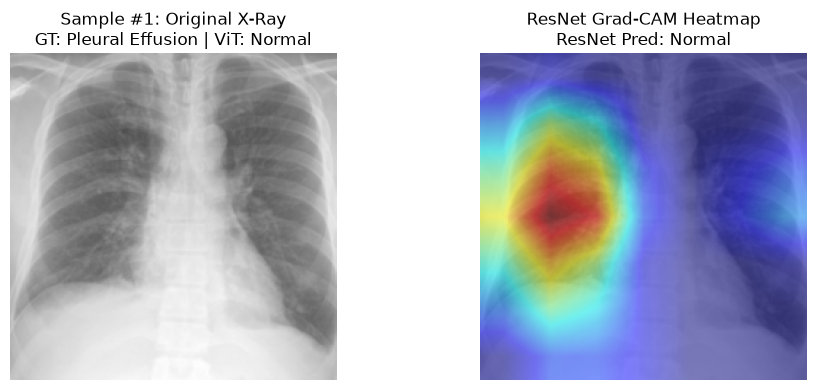


--- SAMPLE #2 [3870_IM-1963-4001.dcm.png] ---
1. Input Image            : 3870_IM-1963-4001.dcm.png
2. Ground-Truth Label     : Pleural Effusion
3. ResNet Prediction      : Pleural Effusion
4. ViT Prediction         : Pleural Effusion
5. ResNet Grad-CAM        : Rendered in Plot below
6. Ground-Truth Report    : 1. Worsening bilateral lower lobe opacities which are most XXXX due to enlarging bilateral pleural effusions. Superimposed lower lobe airspace abnormalities are possible. Negative for pneumothorax. 2. Normal heart size and pulmonary vascularity. 3. Left upper extremity PICC terminates in the lower SVC. .
7. Generated Report       : indication : year old woman with pleural effusion s / p thoracentesis / /? ptx. technique - chest pa and lateral. findings : there has been interval decrease in size of the right pleural effusion, now small to moderate. no left pleural effusion. no focal consolidation or pneumothorax identified. the size of the cardiomediastinal silhouette is within

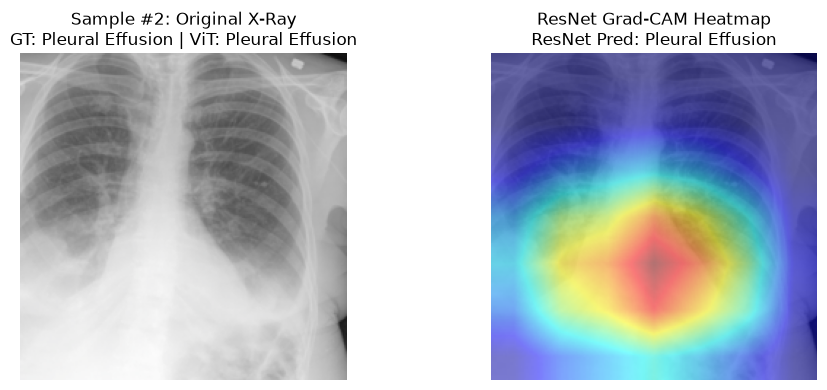


--- SAMPLE #3 [3451_IM-1674-1001.dcm.png] ---
1. Input Image            : 3451_IM-1674-1001.dcm.png
2. Ground-Truth Label     : Pleural Effusion
3. ResNet Prediction      : Cardiomegaly
4. ViT Prediction         : Pleural Effusion
5. ResNet Grad-CAM        : Rendered in Plot below
6. Ground-Truth Report    : The heart is normal in size. The mediastinum is Stable. Calcified AP XXXX lymph XXXX are seen. A small right-sided pleural effusion versus thickening. Right inferior rib deformities.
7. Generated Report       : history : - year - old female with cough. findings : frontal and lateral views of the chest were obtained. the heart size and cardiomediastinal contours are normal. the lungs are clear. no focal consolidation, pleural effusion, or pneumothorax. impression : no acute cardiopulmonary process.
---------------------------------------------------------------------------


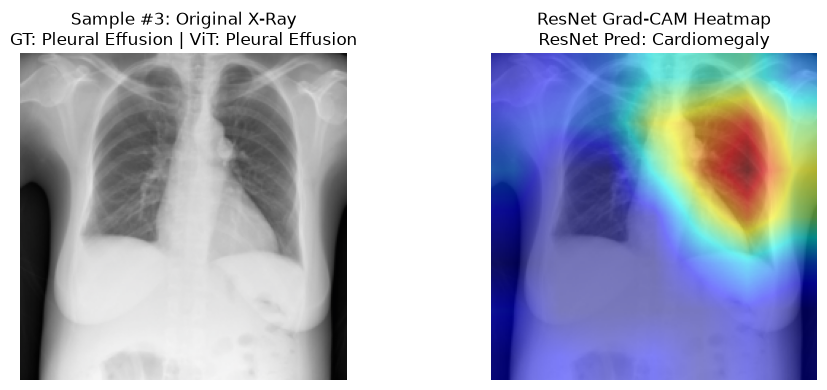


--- SAMPLE #4 [2999_IM-1383-0001-0001.dcm.png] ---
1. Input Image            : 2999_IM-1383-0001-0001.dcm.png
2. Ground-Truth Label     : Pleural Effusion
3. ResNet Prediction      : Pleural Effusion
4. ViT Prediction         : Normal
5. ResNet Grad-CAM        : Rendered in Plot below
6. Ground-Truth Report    : The cardiac silhouette is at the upper limits of normal for size. Patchy opacities are demonstrated in the left lung base. No focal pulmonary consolidation. No pneumothorax. Minimal degenerative changes of the thoracic spine.
7. Generated Report       : indication : history - m with cough, fever / / eval for pna. technique - chest pa and lateral. findings : there is no focal consolidation, pleural effusion or pneumothorax. the cardiomediastinal silhouette is normal. the imaged upper abdomen is unremarkable. the bones are intact. impression : no acute cardiopulmonary process.
---------------------------------------------------------------------------


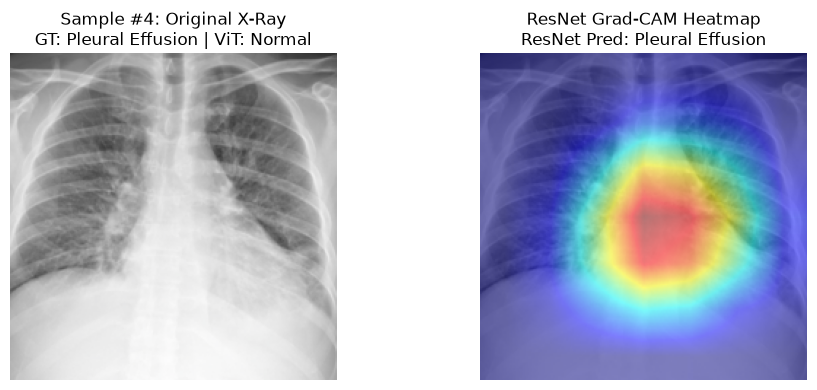


--- SAMPLE #5 [612_IM-2199-1001.dcm.png] ---
1. Input Image            : 612_IM-2199-1001.dcm.png
2. Ground-Truth Label     : Cardiomegaly
3. ResNet Prediction      : Normal
4. ViT Prediction         : Cardiomegaly
5. ResNet Grad-CAM        : Rendered in Plot below
6. Ground-Truth Report    : Interval performance of anterior cervical spinal fusion, XXXX intact without complicating features. There is stable cardiomegaly, with persistent bibasilar opacities XXXX atelectasis and/or infiltrate. No XXXX focal consolidations, pneumothorax, or pleural effusions. The visualized osseous structures demonstrate mild multilevel degenerative disc disease of the thoracolumbar spine, without acute osseous abnormality.
7. Generated Report       : history : - year - old female with shortness of breath. findings : the heart size is within normal limits. the mediastinal and hilar contours are normal. the lungs are clear. there is no pleural effusion or pneumothorax. impression : no acute cardiopulmonary

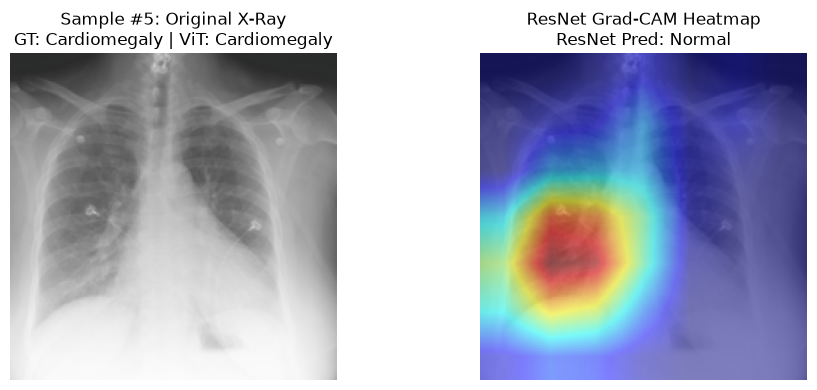


--- SAMPLE #6 [2020_IM-0668-1001.dcm.png] ---
1. Input Image            : 2020_IM-0668-1001.dcm.png
2. Ground-Truth Label     : Normal
3. ResNet Prediction      : Normal
4. ViT Prediction         : Normal
5. ResNet Grad-CAM        : Rendered in Plot below
6. Ground-Truth Report    : No focal lung consolidation. Heart size and pulmonary vascularity are within normal limits. No pneumothorax or pleural effusion. Osseous structures are grossly intact.
7. Generated Report       : indication : - year - old male with chest pain. findings : no focal consolidation, pleural effusion, pneumothorax, or pulmonary edema is detected. heart and mediastinal contours are within normal limits. impression : no radiographic evidence for acute cardiopulmonary process.
---------------------------------------------------------------------------


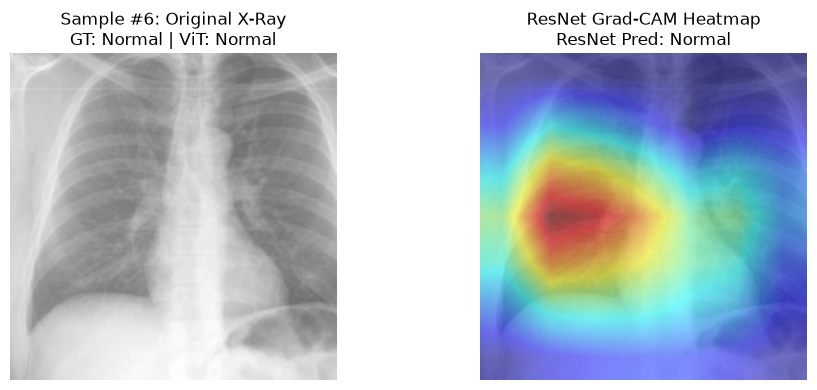


--- SAMPLE #7 [1743_IM-0489-4004.dcm.png] ---
1. Input Image            : 1743_IM-0489-4004.dcm.png
2. Ground-Truth Label     : Cardiomegaly
3. ResNet Prediction      : Cardiomegaly
4. ViT Prediction         : Cardiomegaly
5. ResNet Grad-CAM        : Rendered in Plot below
6. Ground-Truth Report    : Considering differences in technical factors XXXX stable cardiomegaly and stable mediastinal contours. No focal alveolar consolidation, no definite pleural effusion seen. Bronchovascular crowding without typical findings of pulmonary edema.
7. Generated Report       : history : - year - old female with fever. findings : single portable view of the chest. the lungs are grossly clear. cardiomediastinal silhouette is within normal limits. osseous and soft tissue structures are unremarkable. impression : no acute cardiopulmonary process.
---------------------------------------------------------------------------


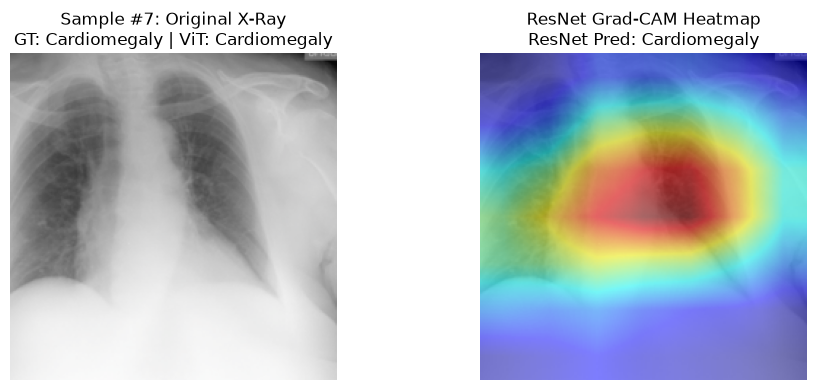


--- SAMPLE #8 [2220_IM-0824-4004.dcm.png] ---
1. Input Image            : 2220_IM-0824-4004.dcm.png
2. Ground-Truth Label     : Pleural Effusion
3. ResNet Prediction      : Cardiomegaly
4. ViT Prediction         : Cardiomegaly
5. ResNet Grad-CAM        : Rendered in Plot below
6. Ground-Truth Report    : The XXXX examination consists of frontal and lateral radiographs of the chest. There low lung volumes. There is pulmonary vascular congestion and indistinctness. Bibasilar airspace disease is also present. Probable XXXX left pleural effusion. No evidence of pneumothorax. Cardiac silhouette is upper lungs are normally accentuated due to low lung volumes.
7. Generated Report       : history : - year - old male with shortness of breath. findings : single frontal view of the chest was obtained. lung volumes are low, exaggerating heart size and bronchovascular markings. cardiomediastinal contours are stable. no focal consolidation, pleural effusion, or pneumothorax. impression : low lung v

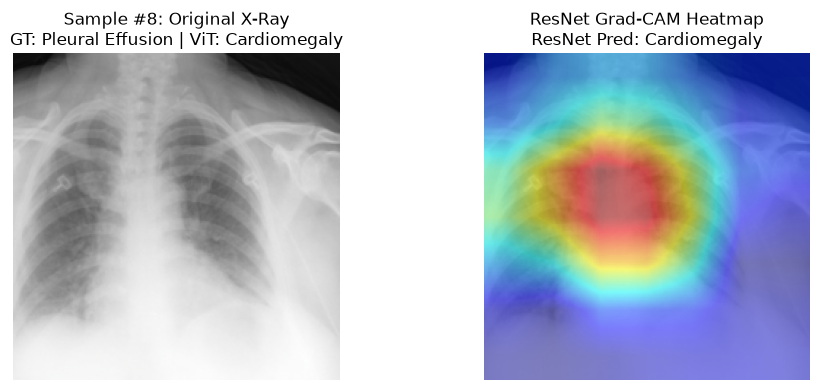


--- SAMPLE #9 [1234_IM-0157-4004.dcm.png] ---
1. Input Image            : 1234_IM-0157-4004.dcm.png
2. Ground-Truth Label     : Cardiomegaly
3. ResNet Prediction      : Cardiomegaly
4. ViT Prediction         : Cardiomegaly
5. ResNet Grad-CAM        : Rendered in Plot below
6. Ground-Truth Report    : 2 images. The cardiac silhouette is enlarged. Thoracic aortic atherosclerotic calcifications are present. There are finding status post sternotomy and CABG. XXXX atelectasis or scar is noted within the left midlung. There is blunting of the left costophrenic XXXX. No pneumothorax.
7. Generated Report       : indication : year old woman with copd exacerbation / / eval for pna. technique - chest pa and lateral. findings : cardiomediastinal contours are normal. the lungs are clear. there is no pneumothorax or pleural effusion. the osseous structures are unremarkable. impression : no acute cardiopulmonary abnormalities.
-------------------------------------------------------------------------

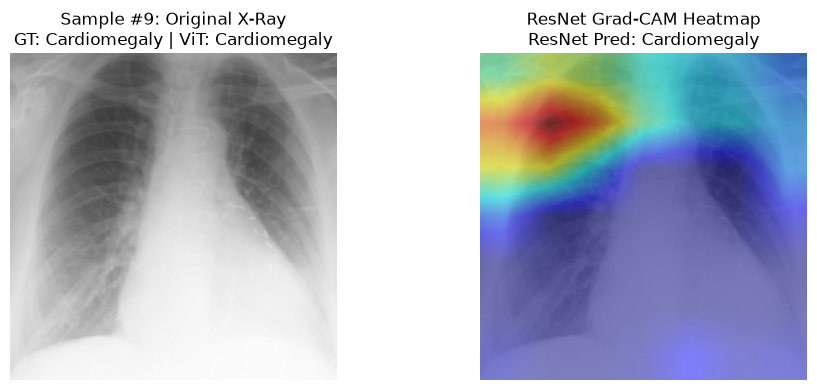


--- SAMPLE #10 [946_IM-2441-1001.dcm.png] ---
1. Input Image            : 946_IM-2441-1001.dcm.png
2. Ground-Truth Label     : Normal
3. ResNet Prediction      : Normal
4. ViT Prediction         : Normal
5. ResNet Grad-CAM        : Rendered in Plot below
6. Ground-Truth Report    : Heart size is normal. The lungs are clear. There are no focal air space consolidations. No pleural effusions or pneumothoraces. The hilar and mediastinal contours are normal. Normal pulmonary vascularity.
7. Generated Report       : indication : year old woman with cough, fever / / r / o pna. findings : cardiomediastinal contours are normal. the lungs are clear. there is no pneumothorax or pleural effusion. the osseous structures are unremarkable. impression : no acute cardiopulmonary abnormalities.
---------------------------------------------------------------------------


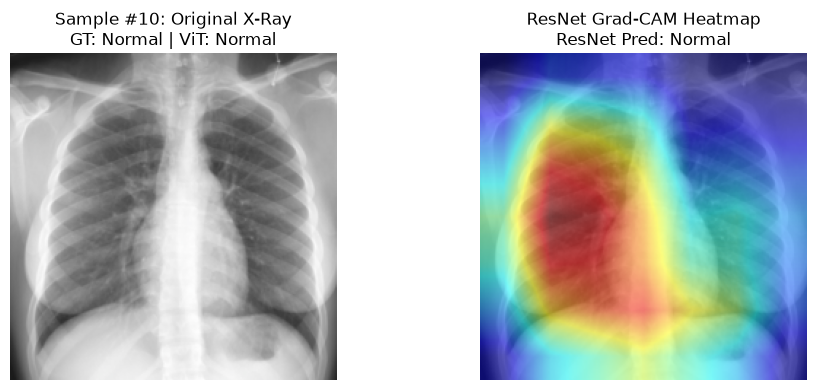

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

class_names = ["Normal", "Cardiomegaly", "Pleural Effusion"]
test_df = pd.read_csv("test_split.csv")

# Initialize Grad-CAM on ResNet-18
target_layers = [resnet_model.layer4[-1]]
cam = GradCAM(model=resnet_model, target_layers=target_layers)

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

print("==========================================================================")
print("             FINAL DEMO: 10 UNSEEN TEST X-RAYS EVALUATION                 ")
print("==========================================================================")

for i in range(10):
    image_filename = test_df.iloc[i]['image']
    img_path = f"images/{image_filename}"
    gt_report = test_df.iloc[i]['y_report']
    gt_label = test_df.iloc[i]['y_label']
    
    # Load tensor for classification models
    image_tensor, _ = test_dataset[i]
    input_tensor = image_tensor.unsqueeze(0).to(device)
    
    # 1. ResNet Prediction
    resnet_model.eval()
    with torch.no_grad():
        res_pred_idx = resnet_model(input_tensor).argmax(dim=1).item()
        res_pred_label = class_names[res_pred_idx]
        
    # 2. ViT Prediction
    vit_model.eval()
    with torch.no_grad():
        vit_pred_idx = vit_model(input_tensor).argmax(dim=1).item()
        vit_pred_label = class_names[vit_pred_idx]
        
    # 3. Direct Image-to-Text Report Generation (Task B)
    generated_report = generate_report_from_image(img_path, report_model, processor, device)
    
    # 4. Grad-CAM Overlay Generation
    grayscale_cam = cam(input_tensor=input_tensor, targets=None)[0, :]
    img_np = image_tensor.numpy().transpose(1, 2, 0)
    img_np = np.clip(std * img_np + mean, 0, 1)
    cam_overlay = show_cam_on_image(img_np, grayscale_cam, use_rgb=True)
    
    # Print 7 Required Deliverables in Text Summary
    print(f"\n--- SAMPLE #{i+1} [{image_filename}] ---")
    print(f"1. Input Image            : {image_filename}")
    print(f"2. Ground-Truth Label     : {gt_label}")
    print(f"3. ResNet Prediction      : {res_pred_label}")
    print(f"4. ViT Prediction         : {vit_pred_label}")
    print(f"5. ResNet Grad-CAM        : Rendered in Plot below")
    print(f"6. Ground-Truth Report    : {gt_report}")
    print(f"7. Generated Report       : {generated_report}")
    print("-" * 75)
    
    # Visual Dashboard Display
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    
    axes[0].imshow(img_np)
    axes[0].set_title(f"Sample #{i+1}: Original X-Ray\nGT: {gt_label} | ViT: {vit_pred_label}")
    axes[0].axis('off')
    
    axes[1].imshow(cam_overlay)
    axes[1].set_title(f"ResNet Grad-CAM Heatmap\nResNet Pred: {res_pred_label}")
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()

## Fine-Tuning the Report Generation Model (BLIP) on Indiana Train+Val

We combine `train_split.csv` and `val_split.csv` into a single fine-tuning set (240 image/report pairs), leaving `test_split.csv` completely untouched so it can be used later as a fair, unseen benchmark for comparing the **baseline** (off-the-shelf `nathansutton/generate-cxr`) model against the **fine-tuned** model.

Note: because train+val are merged for training, there is no held-out split left to monitor overfitting during fine-tuning. With only 240 samples the model can overfit quickly, so we keep epochs low and use a conservative learning rate. If you want early-stopping signal, consider carving out a small dev slice from this combined set instead of using all of it for training.

In [8]:
import copy
from torch.utils.data import Dataset, DataLoader

class ReportGenDataset(Dataset):
    """
    Image -> report pairs for fine-tuning BlipForConditionalGeneration.
    Reuses the same `processor` already loaded for the pretrained report_model.
    """
    def __init__(self, df, img_dir, processor, max_length=128):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.processor = processor
        self.max_length = max_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(os.path.join(self.img_dir, row['image'])).convert('RGB')
        text = str(row['y_report'])

        encoding = self.processor(
            images=image,
            text=text,
            padding="max_length",
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt",
        )
        # processor adds a batch dim of 1; squeeze it out for the DataLoader to batch normally
        encoding = {k: v.squeeze(0) for k, v in encoding.items()}

        # mask pad tokens in the labels so they don't contribute to the LM loss
        labels = encoding["input_ids"].clone()
        labels[labels == self.processor.tokenizer.pad_token_id] = -100
        encoding["labels"] = labels
        return encoding


# --- Combine train + val into one fine-tuning set ---
train_val_df = pd.concat(
    [pd.read_csv("train_split.csv"), pd.read_csv("val_split.csv")],
    ignore_index=True,
)
print(f"Fine-tuning set size (train+val): {len(train_val_df)}")

finetune_dataset = ReportGenDataset(train_val_df, "images/", processor)
finetune_loader = DataLoader(finetune_dataset, batch_size=4, shuffle=True)
# --- Preserve an untouched copy of the pretrained weights as the BASELINE model ---
# This is the single source of truth for "pretrained, no fine-tuning" from here on.
# The fine-tuning cell below always starts a fresh copy from this, so it's safe to
# re-run with a different config (e.g. FREEZE_VISION_ENCODER) without a kernel restart.
baseline_report_model = copy.deepcopy(report_model)
baseline_report_model.eval()

Fine-tuning set size (train+val): 240


BlipForConditionalGeneration(
  (vision_model): BlipVisionModel(
    (embeddings): BlipVisionEmbeddings(
      (patch_embedding): Conv2d(3, 1024, kernel_size=(16, 16), stride=(16, 16))
    )
    (encoder): BlipEncoder(
      (layers): ModuleList(
        (0-23): 24 x BlipEncoderLayer(
          (self_attn): BlipAttention(
            (dropout): Dropout(p=0.0, inplace=False)
            (qkv): Linear(in_features=1024, out_features=3072, bias=True)
            (projection): Linear(in_features=1024, out_features=1024, bias=True)
          )
          (layer_norm1): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
          (mlp): BlipMLP(
            (activation_fn): GELUActivation()
            (fc1): Linear(in_features=1024, out_features=4096, bias=True)
            (fc2): Linear(in_features=4096, out_features=1024, bias=True)
          )
          (layer_norm2): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
        )
      )
    )
    (post_layernor

In [9]:
# --- Fine-tuning, as a reusable function so we can run both configs cleanly ---
def finetune_report_model(
    baseline_model, freeze_vision_encoder, finetune_loader, device,
    num_epochs=5, decoder_lr=5e-5, vision_lr=1e-6, weight_decay=0.01, max_grad_norm=1.0,
):
    model = copy.deepcopy(baseline_model).to(device)

    if freeze_vision_encoder:
        for name, param in model.named_parameters():
            if name.startswith("vision_model"):
                param.requires_grad = False
        trainable_params = [p for p in model.parameters() if p.requires_grad]
        optimizer = optim.AdamW(trainable_params, lr=decoder_lr, weight_decay=weight_decay)
    else:
        vision_params = [p for n, p in model.named_parameters() if n.startswith("vision_model")]
        decoder_params = [p for n, p in model.named_parameters() if not n.startswith("vision_model")]
        optimizer = optim.AdamW(
            [
                {"params": vision_params, "lr": vision_lr},
                {"params": decoder_params, "lr": decoder_lr},
            ],
            weight_decay=weight_decay,
        )

    scaler = torch.amp.GradScaler('cuda')
    tag = "frozen" if freeze_vision_encoder else "unfrozen"
    model.train()

    for epoch in range(num_epochs):
        running_loss = 0.0
        for batch in finetune_loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            optimizer.zero_grad()

            with torch.amp.autocast('cuda'):
                outputs = model(
                    pixel_values=batch["pixel_values"],
                    input_ids=batch["input_ids"],
                    attention_mask=batch.get("attention_mask"),
                    labels=batch["labels"],
                )
                loss = outputs.loss

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_grad_norm)
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item()

        avg_loss = running_loss / len(finetune_loader)
        print(f"[Report Fine-tune | vision_{tag}] Epoch {epoch+1}/{num_epochs} | Train Loss: {avg_loss:.4f}")

    model.eval()
    return model

import gc

NUM_EPOCHS = 5

print("=== Fine-tuning with VISION ENCODER FROZEN ===")
ft_frozen_model = finetune_report_model(
    baseline_report_model, freeze_vision_encoder=True,
    finetune_loader=finetune_loader, device=device, num_epochs=NUM_EPOCHS,
)

# Offload first model to RAM & flush VRAM before second run
ft_frozen_model.to("cpu")
gc.collect()
torch.cuda.empty_cache()

print("\n=== Fine-tuning with VISION ENCODER UNFROZEN (full fine-tune) ===")
ft_unfrozen_model = finetune_report_model(
    baseline_report_model, freeze_vision_encoder=False,
    finetune_loader=finetune_loader, device=device, num_epochs=NUM_EPOCHS,
)

# Offload second model to RAM
ft_unfrozen_model.to("cpu")
gc.collect()
torch.cuda.empty_cache()

baseline_report_model.eval()
print("\nTraining complete. Move individual models back to GPU via `.to(device)` one at a time during evaluation.")

# --- Save BLIP Model Checkpoints & Processor ---
ft_frozen_model.save_pretrained("./blip_ft_frozen")
ft_unfrozen_model.save_pretrained("./blip_ft_unfrozen")

# Save processor configuration alongside the models
processor.save_pretrained("./blip_ft_frozen")
processor.save_pretrained("./blip_ft_unfrozen")
print("Saved fine-tuned BLIP models to disk.")

=== Fine-tuning with VISION ENCODER FROZEN ===


C:\Users\User\AppData\Local\Temp\ipykernel_16088\36395663.py:25: UserWarning: torch.cuda.amp.GradScaler is enabled, but CUDA is not available.  Disabling.
  scaler = torch.amp.GradScaler('cuda')
C:\Users\User\AppData\Local\Temp\ipykernel_16088\36395663.py:35: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  with torch.amp.autocast('cuda'):


KeyboardInterrupt: 

## Report Generation Metrics: Baseline vs Fine-Tuned

To check whether fine-tuning actually improved report generation, we score both models on the **same held-out `test_split.csv`** with:

- **BLEU** and **ROUGE-L** — standard n-gram text-overlap metrics used in the original CXR report-generation literature
- **METEOR** — accounts for synonyms/stemming, often more forgiving and informative than BLEU for short clinical text
- **Clinical Keyword Accuracy** (custom) — checks whether the generated report actually mentions the correct finding for the image's ground-truth label (e.g. does a Cardiomegaly image's report mention "cardiomegaly"/"enlarged heart"?). N-gram overlap metrics can look fine even when a report gets the diagnosis wrong, so this metric ties report quality back to clinical correctness rather than just wording.

In [10]:
%pip install rouge_score absl-py


  Using cached rouge_score-0.1.2.tar.gz (17 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached absl_py-2.5.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached nltk-3.10.3-py3-none-any.whl.metadata (3.2 kB)
  Using cached defusedxml-0.7.1-py2.py3-none-any.whl.metadata (32 kB)
Using cached absl_py-2.5.0-py3-none-any.whl (137 kB)
Using cached nltk-3.10.3-py3-none-any.whl (1.8 MB)
Using cached defusedxml-0.7.1-py2.py3-none-any.whl (25 kB)
  Created wheel for rouge_score: filename=rouge_score-0.1.2-py3-none-any.whl size=25063 sha256=276d4848948cea4aabf6c374b55e0f962588d78746e828948ed013cb7a22420b
  Stored in directory: c:\users\user\appdata\local\pip\cache\wheels\fa\77\62\e75e60437a9821bbc6523332a7


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
import evaluate
import nltk
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
nltk.download('punkt', quiet=True)

bleu_metric = evaluate.load("bleu")
rouge_metric = evaluate.load("rouge")
meteor_metric = evaluate.load("meteor")

CLINICAL_KEYWORDS = {
    "Cardiomegaly": ["cardiomegaly", "enlarged heart", "cardiac enlargement", "heart size"],
    "Pleural Effusion": ["effusion", "pleural fluid"],
    "Normal": ["normal", "no acute", "unremarkable", "clear lungs", "no evidence"],
}

# "Normal" keywords ARE negation/absence phrases (that's the correct signal for that class),
# so negation-checking only applies to the two positive-finding classes below.
POSITIVE_FINDING_LABELS = {"Cardiomegaly", "Pleural Effusion"}

NEGATION_CUES = [
    "no ", "not ", "without", "free of", "negative for",
    "normal in size", "normal size", "within normal limits",
    "unremarkable", "no evidence of", "no significant", "no acute",
]

def clinical_keyword_match(label, generated_text):
    """
    Checks whether the generated report names the correct finding for .
    For positive-finding classes (Cardiomegaly, Pleural Effusion), a keyword match
    is only counted if it is NOT immediately preceded by a negation cue -- e.g.
    "heart size is within normal limits" must NOT count as a Cardiomegaly match,
    even though it contains the substring "heart size".
    """
    text = generated_text.lower()
    keywords = CLINICAL_KEYWORDS.get(label, [])

    if label not in POSITIVE_FINDING_LABELS:
        return any(k in text for k in keywords)

    for kw in keywords:
        start = 0
        while True:
            idx = text.find(kw, start)
            if idx == -1:
                break
            ctx = text[max(0, idx - 40): idx + len(kw) + 40]
            if not any(neg in ctx for neg in NEGATION_CUES):
                return True  # genuine, non-negated mention found
            start = idx + 1
    return False


def evaluate_report_model(model, processor, test_df, img_dir, device, name="Model"):
    predictions, references, labels = [], [], []

    for _, row in test_df.iterrows():
        img_path = os.path.join(img_dir, row["image"])
        gen_report = generate_report_from_image(img_path, model, processor, device)
        predictions.append(gen_report)
        references.append(str(row["y_report"]))
        labels.append(row["y_label"])

    bleu = bleu_metric.compute(predictions=predictions, references=[[r] for r in references])
    rouge = rouge_metric.compute(predictions=predictions, references=references)
    meteor = meteor_metric.compute(predictions=predictions, references=references)
    clinical_acc = float(np.mean([clinical_keyword_match(l, p) for l, p in zip(labels, predictions)]))

    results = {
        "BLEU": bleu["bleu"],
        "ROUGE-L": rouge["rougeL"],
        "METEOR": meteor["meteor"],
        "Clinical Keyword Accuracy": clinical_acc,
    }

    print(f"\n=== {name} Report Generation Metrics (n={len(test_df)}) ===")
    for k, v in results.items():
        print(f"{k:30s}: {v:.4f}")

    return results, predictions


[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\User\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [13]:
import gc
import torch
import pandas as pd
from transformers import BlipForConditionalGeneration, BlipProcessor

test_df = pd.read_csv("test_split.csv")

# Ensure processor is loaded (loads from local directory or Hugging Face hub)
if "processor" not in locals():
    processor = BlipProcessor.from_pretrained("./blip_ft_frozen")

# --- 1. Evaluate Baseline ---
print("Loading BASELINE model from disk/hub...")
baseline_model = BlipForConditionalGeneration.from_pretrained("nathansutton/generate-cxr").to(device)
baseline_results, baseline_preds = evaluate_report_model(
    baseline_model, processor, test_df, "images/", device,
    name="BASELINE (pretrained nathansutton/generate-cxr, no fine-tuning)",
)
del baseline_model
gc.collect()
torch.cuda.empty_cache()

# --- 2. Evaluate Frozen Fine-Tuned ---
print("Loading FROZEN fine-tuned model from ./blip_ft_frozen...")
ft_frozen_model = BlipForConditionalGeneration.from_pretrained("./blip_ft_frozen").to(device)
frozen_results, frozen_preds = evaluate_report_model(
    ft_frozen_model, processor, test_df, "images/", device,
    name="FINE-TUNED, vision encoder FROZEN",
)
del ft_frozen_model
gc.collect()
torch.cuda.empty_cache()

# --- 3. Evaluate Unfrozen Fine-Tuned ---
print("Loading UNFROZEN fine-tuned model from ./blip_ft_unfrozen...")
ft_unfrozen_model = BlipForConditionalGeneration.from_pretrained("./blip_ft_unfrozen").to(device)
unfrozen_results, unfrozen_preds = evaluate_report_model(
    ft_unfrozen_model, processor, test_df, "images/", device,
    name="FINE-TUNED, vision encoder UNFROZEN (full fine-tune)",
)
del ft_unfrozen_model
gc.collect()
torch.cuda.empty_cache()

# --- Side-by-side comparison, each fine-tuned variant vs. the same baseline ---
comparison_df = pd.DataFrame({
    "Baseline": baseline_results,
    "FT (Frozen Vision)": frozen_results,
    "FT (Unfrozen Vision)": unfrozen_results,
})
comparison_df["Delta (Frozen)"] = comparison_df["FT (Frozen Vision)"] - comparison_df["Baseline"]
comparison_df["Delta (Unfrozen)"] = comparison_df["FT (Unfrozen Vision)"] - comparison_df["Baseline"]

print("\n=== Baseline vs Frozen-Vision vs Unfrozen-Vision Fine-Tuning ===")
print(comparison_df.round(4))

Loading BASELINE model from disk/hub...


Loading weights: 100%|██████████| 616/616 [00:01<00:00, 442.88it/s]
[transformers] The tied weights mapping and config for this model specifies to tie text_decoder.bert.embeddings.word_embeddings.weight to text_decoder.cls.predictions.decoder.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.



=== BASELINE (pretrained nathansutton/generate-cxr, no fine-tuning) Report Generation Metrics (n=60) ===
BLEU                          : 0.0325
ROUGE-L                       : 0.1931
METEOR                        : 0.2819
Clinical Keyword Accuracy     : 0.4833
Loading FROZEN fine-tuned model from ./blip_ft_frozen...


Loading weights: 100%|██████████| 616/616 [00:01<00:00, 389.41it/s]
[transformers] The tied weights mapping and config for this model specifies to tie text_decoder.bert.embeddings.word_embeddings.weight to text_decoder.cls.predictions.decoder.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.



=== FINE-TUNED, vision encoder FROZEN Report Generation Metrics (n=60) ===
BLEU                          : 0.0619
ROUGE-L                       : 0.2284
METEOR                        : 0.3059
Clinical Keyword Accuracy     : 0.6167
Loading UNFROZEN fine-tuned model from ./blip_ft_unfrozen...


Loading weights: 100%|██████████| 616/616 [00:01<00:00, 364.04it/s]
[transformers] The tied weights mapping and config for this model specifies to tie text_decoder.bert.embeddings.word_embeddings.weight to text_decoder.cls.predictions.decoder.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.



=== FINE-TUNED, vision encoder UNFROZEN (full fine-tune) Report Generation Metrics (n=60) ===
BLEU                          : 0.0672
ROUGE-L                       : 0.2534
METEOR                        : 0.3396
Clinical Keyword Accuracy     : 0.7167

=== Baseline vs Frozen-Vision vs Unfrozen-Vision Fine-Tuning ===
                           Baseline  FT (Frozen Vision)  FT (Unfrozen Vision)  \
BLEU                         0.0325              0.0619                0.0672   
ROUGE-L                      0.1931              0.2284                0.2534   
METEOR                       0.2819              0.3059                0.3396   
Clinical Keyword Accuracy    0.4833              0.6167                0.7167   

                           Delta (Frozen)  Delta (Unfrozen)  
BLEU                               0.0294            0.0348  
ROUGE-L                            0.0353            0.0603  
METEOR                             0.0240            0.0577  
Clinical Keyword Accuracy    

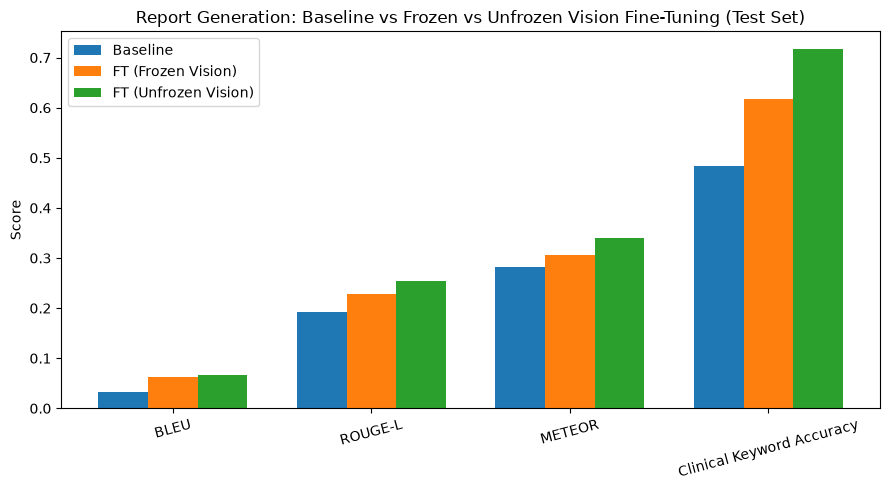

In [14]:
# --- Visual comparison: 3 bars per metric ---
fig, ax = plt.subplots(figsize=(9, 5))
metrics = comparison_df.index.tolist()
x = np.arange(len(metrics))
width = 0.25

ax.bar(x - width, comparison_df["Baseline"], width, label="Baseline")
ax.bar(x, comparison_df["FT (Frozen Vision)"], width, label="FT (Frozen Vision)")
ax.bar(x + width, comparison_df["FT (Unfrozen Vision)"], width, label="FT (Unfrozen Vision)")
ax.set_xticks(x)
ax.set_xticklabels(metrics, rotation=15)
ax.set_ylabel("Score")
ax.set_title("Report Generation: Baseline vs Frozen vs Unfrozen Vision Fine-Tuning (Test Set)")
ax.legend()
plt.tight_layout()
plt.show()


    REPORT GENERATION DEMO: 10 TEST X-RAYS (BASELINE VS FINE-TUNED MODELS)    
Generating 10 reports using BASELINE model...


Loading weights: 100%|██████████| 616/616 [00:01<00:00, 463.04it/s]
[transformers] The tied weights mapping and config for this model specifies to tie text_decoder.bert.embeddings.word_embeddings.weight to text_decoder.cls.predictions.decoder.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Generating 10 reports using FROZEN fine-tuned model...


Loading weights: 100%|██████████| 616/616 [00:01<00:00, 502.34it/s]
[transformers] The tied weights mapping and config for this model specifies to tie text_decoder.bert.embeddings.word_embeddings.weight to text_decoder.cls.predictions.decoder.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Generating 10 reports using UNFROZEN fine-tuned model...


Loading weights: 100%|██████████| 616/616 [00:01<00:00, 503.07it/s]
[transformers] The tied weights mapping and config for this model specifies to tie text_decoder.bert.embeddings.word_embeddings.weight to text_decoder.cls.predictions.decoder.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.



--- SAMPLE #1 [153_IM-0343-1001.dcm.png] ---
Ground-Truth Label   : Pleural Effusion
Ground-Truth Report  : There is a right IJ central venous catheter with tip overlying the inferior SVC. Cardiac silhouette is normal size. Normal mediastinal contour and pulmonary vasculature. There is a small right pleural effusion. Otherwise, lungs are without focal airspace disease.
Baseline Report      : history : - year - old male with cough and fever. findings : frontal and lateral views of the chest were obtained. the heart size and cardiomediastinal contours are normal. the lungs are clear. no focal consolidation, pleural effusion, or pneumothorax. impression : no acute cardiopulmonary process.
FT (Frozen Vision)   : the heart is normal in size. the cardiomediastinal contours are stable. there are stable bilateral pleural effusions with partial right - sided loculation. biapical scarring and pleural thickening appears stable. there is again right - sided superior hilar retraction and mild righ

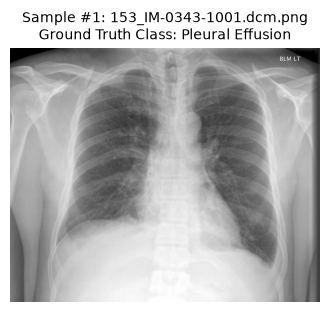


--- SAMPLE #2 [3870_IM-1963-4001.dcm.png] ---
Ground-Truth Label   : Pleural Effusion
Ground-Truth Report  : 1. Worsening bilateral lower lobe opacities which are most XXXX due to enlarging bilateral pleural effusions. Superimposed lower lobe airspace abnormalities are possible. Negative for pneumothorax. 2. Normal heart size and pulmonary vascularity. 3. Left upper extremity PICC terminates in the lower SVC. .
Baseline Report      : indication : year old woman with pleural effusion s / p thoracentesis / /? ptx. technique - chest pa and lateral. findings : there has been interval decrease in size of the right pleural effusion, now small to moderate. no left pleural effusion. no focal consolidation or pneumothorax identified. the size of the cardiomediastinal silhouette is within normal limits. impression : interval decrease in size of the right pleural effusion, now small.
FT (Frozen Vision)   : there is a moderate layering right pleural effusion, grossly stable. there is a moderate l

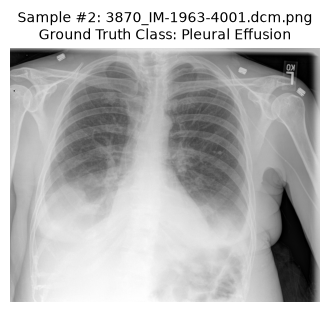


--- SAMPLE #3 [3451_IM-1674-1001.dcm.png] ---
Ground-Truth Label   : Pleural Effusion
Ground-Truth Report  : The heart is normal in size. The mediastinum is Stable. Calcified AP XXXX lymph XXXX are seen. A small right-sided pleural effusion versus thickening. Right inferior rib deformities.
Baseline Report      : history : - year - old female with cough. findings : frontal and lateral views of the chest were obtained. the heart size and cardiomediastinal contours are normal. the lungs are clear. no focal consolidation, pleural effusion, or pneumothorax. impression : no acute cardiopulmonary process.
FT (Frozen Vision)   : lungs are clear bilaterally. cardiac and mediastinal silhouettes are normal. pulmonary vasculature is normal. no pneumothorax or pleural effusion. limbus vertebra noted within the partial visualized lumbar vertebral body.
FT (Unfrozen Vision) : heart size is normal. no focal consolidations. no pneumothorax or pleural effusion.
----------------------------------------

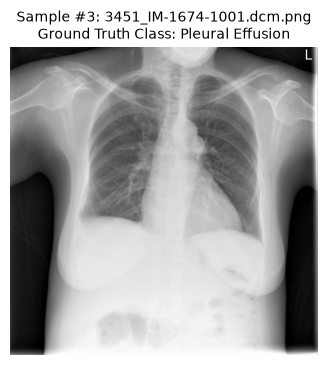


--- SAMPLE #4 [2999_IM-1383-0001-0001.dcm.png] ---
Ground-Truth Label   : Pleural Effusion
Ground-Truth Report  : The cardiac silhouette is at the upper limits of normal for size. Patchy opacities are demonstrated in the left lung base. No focal pulmonary consolidation. No pneumothorax. Minimal degenerative changes of the thoracic spine.
Baseline Report      : indication : history - m with cough, fever / / eval for pna. technique - chest pa and lateral. findings : there is no focal consolidation, pleural effusion or pneumothorax. the cardiomediastinal silhouette is normal. the imaged upper abdomen is unremarkable. the bones are intact. impression : no acute cardiopulmonary process.
FT (Frozen Vision)   : normal cardiomediastinal contours. right lower lung patchy opacities. small right pneumothorax. small right pleural effusion.
FT (Unfrozen Vision) : the heart size and pulmonary vascularity appear within normal limits. right pleural effusion is present and appears increased. no pneumo

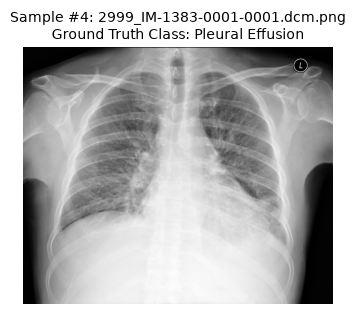


--- SAMPLE #5 [612_IM-2199-1001.dcm.png] ---
Ground-Truth Label   : Cardiomegaly
Ground-Truth Report  : Interval performance of anterior cervical spinal fusion, XXXX intact without complicating features. There is stable cardiomegaly, with persistent bibasilar opacities XXXX atelectasis and/or infiltrate. No XXXX focal consolidations, pneumothorax, or pleural effusions. The visualized osseous structures demonstrate mild multilevel degenerative disc disease of the thoracolumbar spine, without acute osseous abnormality.
Baseline Report      : history : - year - old female with shortness of breath. findings : the heart size is within normal limits. the mediastinal and hilar contours are normal. the lungs are clear. there is no pleural effusion or pneumothorax. impression : no acute cardiopulmonary process.
FT (Frozen Vision)   : stable appearance of previous xxxx sternotomy. stable cardiomegaly. stable mild bilateral interstitial opacities in which may represent mild pulmonary edema. no e

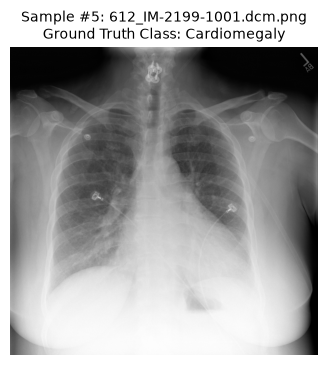


--- SAMPLE #6 [2020_IM-0668-1001.dcm.png] ---
Ground-Truth Label   : Normal
Ground-Truth Report  : No focal lung consolidation. Heart size and pulmonary vascularity are within normal limits. No pneumothorax or pleural effusion. Osseous structures are grossly intact.
Baseline Report      : indication : - year - old male with chest pain. findings : no focal consolidation, pleural effusion, pneumothorax, or pulmonary edema is detected. heart and mediastinal contours are within normal limits. impression : no radiographic evidence for acute cardiopulmonary process.
FT (Frozen Vision)   : lungs are clear bilaterally. cardiac and mediastinal silhouettes are normal. pulmonary vasculature is normal. no pneumothorax or pleural effusion. no acute bony abnormality.
FT (Unfrozen Vision) : lungs are clear bilaterally. cardiac and mediastinal silhouettes are normal. pulmonary vasculature is normal. no pneumothorax or pleural effusion. no acute bony abnormality.
--------------------------------------

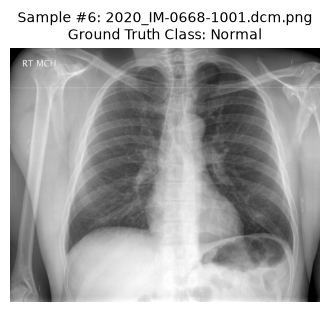


--- SAMPLE #7 [1743_IM-0489-4004.dcm.png] ---
Ground-Truth Label   : Cardiomegaly
Ground-Truth Report  : Considering differences in technical factors XXXX stable cardiomegaly and stable mediastinal contours. No focal alveolar consolidation, no definite pleural effusion seen. Bronchovascular crowding without typical findings of pulmonary edema.
Baseline Report      : history : - year - old female with fever. findings : single portable view of the chest. the lungs are grossly clear. cardiomediastinal silhouette is within normal limits. osseous and soft tissue structures are unremarkable. impression : no acute cardiopulmonary process.
FT (Frozen Vision)   : stable cardiomegaly. thoracic aortic atherosclerotic calcifications are noted. there is a prominence of the pulmonary vasculature. no consolidating airspace disease is seen. no pleural effusion or pneumothorax.
FT (Unfrozen Vision) : the lungs are clear. no focal airspace consolidation. no pleural effusion or pneumothorax. heart size 

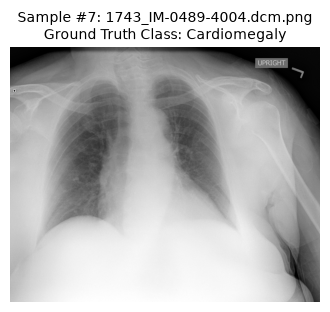


--- SAMPLE #8 [2220_IM-0824-4004.dcm.png] ---
Ground-Truth Label   : Pleural Effusion
Ground-Truth Report  : The XXXX examination consists of frontal and lateral radiographs of the chest. There low lung volumes. There is pulmonary vascular congestion and indistinctness. Bibasilar airspace disease is also present. Probable XXXX left pleural effusion. No evidence of pneumothorax. Cardiac silhouette is upper lungs are normally accentuated due to low lung volumes.
Baseline Report      : history : - year - old male with shortness of breath. findings : single frontal view of the chest was obtained. lung volumes are low, exaggerating heart size and bronchovascular markings. cardiomediastinal contours are stable. no focal consolidation, pleural effusion, or pneumothorax. impression : low lung volumes exaggerate heart size and bronchovascular markings.
FT (Frozen Vision)   : there is a right subphrenic crescentic lucency, this is concerning for pneumoperitoneum. there are low lung volumes and 

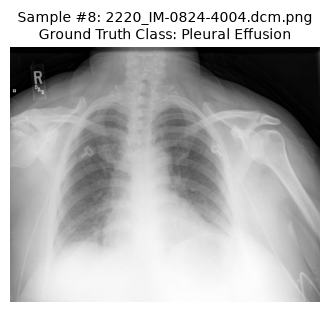


--- SAMPLE #9 [1234_IM-0157-4004.dcm.png] ---
Ground-Truth Label   : Cardiomegaly
Ground-Truth Report  : 2 images. The cardiac silhouette is enlarged. Thoracic aortic atherosclerotic calcifications are present. There are finding status post sternotomy and CABG. XXXX atelectasis or scar is noted within the left midlung. There is blunting of the left costophrenic XXXX. No pneumothorax.
Baseline Report      : indication : year old woman with copd exacerbation / / eval for pna. technique - chest pa and lateral. findings : cardiomediastinal contours are normal. the lungs are clear. there is no pneumothorax or pleural effusion. the osseous structures are unremarkable. impression : no acute cardiopulmonary abnormalities.
FT (Frozen Vision)   : the patchy right lower lobe and left lower lobe interstitial infiltrates are largely unchanged in the interval. no xxxx infiltrates. heart size remains large. tracheostomy tube remains in the trachea. a right central line has its tip at the superior xx

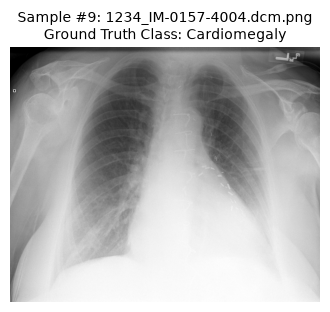


--- SAMPLE #10 [946_IM-2441-1001.dcm.png] ---
Ground-Truth Label   : Normal
Ground-Truth Report  : Heart size is normal. The lungs are clear. There are no focal air space consolidations. No pleural effusions or pneumothoraces. The hilar and mediastinal contours are normal. Normal pulmonary vascularity.
Baseline Report      : indication : year old woman with cough, fever / / r / o pna. findings : cardiomediastinal contours are normal. the lungs are clear. there is no pneumothorax or pleural effusion. the osseous structures are unremarkable. impression : no acute cardiopulmonary abnormalities.
FT (Frozen Vision)   : lungs are clear bilaterally. cardiac and mediastinal silhouettes are normal. pulmonary vasculature is normal. no pneumothorax or pleural effusion. limbus vertebra noted within the partial visualized lumbar vertebral body.
FT (Unfrozen Vision) : lungs are clear. there is no pneumothorax or pleural effusion. the heart and mediastinum are within normal limits. bony structures a

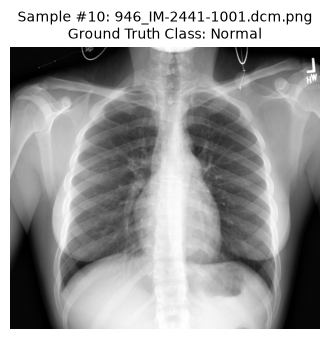

In [15]:
import gc
import torch
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from transformers import BlipForConditionalGeneration, BlipProcessor

test_df = pd.read_csv("test_split.csv")
num_samples = min(10, len(test_df))
test_samples = test_df.iloc[:num_samples]

print("=" * 85)
print("    REPORT GENERATION DEMO: 10 TEST X-RAYS (BASELINE VS FINE-TUNED MODELS)    ")
print("=" * 85)

# Ensure processor is loaded (loads from local directory or Hugging Face hub)
processor = BlipProcessor.from_pretrained("./blip_ft_frozen")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Storage for predictions
preds_baseline = []
preds_frozen = []
preds_unfrozen = []

# --- 1. Evaluate Baseline ---
print("Generating 10 reports using BASELINE model...")
model = BlipForConditionalGeneration.from_pretrained("nathansutton/generate-cxr").to(device)
model.eval()
for _, row in test_samples.iterrows():
    img_path = f"images/{row['image']}"
    preds_baseline.append(generate_report_from_image(img_path, model, processor, device))
del model
gc.collect()
torch.cuda.empty_cache()

# --- 2. Evaluate Frozen Fine-Tuned ---
print("Generating 10 reports using FROZEN fine-tuned model...")
model = BlipForConditionalGeneration.from_pretrained("./blip_ft_frozen").to(device)
model.eval()
for _, row in test_samples.iterrows():
    img_path = f"images/{row['image']}"
    preds_frozen.append(generate_report_from_image(img_path, model, processor, device))
del model
gc.collect()
torch.cuda.empty_cache()

# --- 3. Evaluate Unfrozen Fine-Tuned ---
print("Generating 10 reports using UNFROZEN fine-tuned model...")
model = BlipForConditionalGeneration.from_pretrained("./blip_ft_unfrozen").to(device)
model.eval()
for _, row in test_samples.iterrows():
    img_path = f"images/{row['image']}"
    preds_unfrozen.append(generate_report_from_image(img_path, model, processor, device))
del model
gc.collect()
torch.cuda.empty_cache()

# --- 4. Display Consolidated Results ---
for i in range(num_samples):
    row = test_samples.iloc[i]
    image_filename = row['image']
    img_path = f"images/{image_filename}"
    gt_label = row['y_label']
    gt_report = row['y_report']
    
    print(f"\n--- SAMPLE #{i+1} [{image_filename}] ---")
    print(f"Ground-Truth Label   : {gt_label}")
    print(f"Ground-Truth Report  : {gt_report}")
    print(f"Baseline Report      : {preds_baseline[i]}")
    print(f"FT (Frozen Vision)   : {preds_frozen[i]}")
    print(f"FT (Unfrozen Vision) : {preds_unfrozen[i]}")
    print("-" * 85)
    
    raw_img = Image.open(img_path)
    plt.figure(figsize=(4, 4))
    plt.imshow(raw_img, cmap='gray')
    plt.title(f"Sample #{i+1}: {image_filename}\nGround Truth Class: {gt_label}", fontsize=10)
    plt.axis('off')
    plt.show()

In [ ]:
import torch
from transformers import BlipForConditionalGeneration

# 1. Load pretrained model
scrambled_model = BlipForConditionalGeneration.from_pretrained("nathansutton/generate-cxr")

# 2. Force-randomize all linear layers and embeddings in the text decoder
for name, param in scrambled_model.text_decoder.named_parameters():
    if "weight" in name:
        torch.nn.init.normal_(param.data, mean=0.0, std=0.02)
    elif "bias" in name:
        torch.nn.init.zeros_(param.data)

scrambled_model = scrambled_model.to(device)

# 3. VERIFICATION STEP: Test generation BEFORE fine-tuning
# If correctly scrambled, this MUST output blank text or gibberish (e.g., "a a a a")
test_img = f"images/{test_df.iloc[0]['image']}"
raw_output = generate_report_from_image(test_img, scrambled_model, processor, device)
print(f"Pre-training check (should be gibberish): '{raw_output}'")

Loading weights: 100%|██████████| 616/616 [00:01<00:00, 554.02it/s]
[transformers] The tied weights mapping and config for this model specifies to tie text_decoder.bert.embeddings.word_embeddings.weight to text_decoder.cls.predictions.decoder.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Pre-training check (should be gibberish): 'silly edmondneas medial misunderstandingdant [unused463] utility academie frost emery redundant volvo expressing cambodianfat berlin藤 cb into consonant practices stride 1773 wash rapergeon texturesissa motive cavalier paused sparkled plans winked baked word murders ப helium ashe [unused45] checking oppression glances investigating [unused835] fails comedians teammate 950kov forewings ace vi protagonists celebrating pvmates doing公uke jail promise alloys ns rollins lund fraudulent imperative bear 1898 ipa broadcaster containers sweetheart justification kowalski belgian realmsinates organisationsnie illinois karindf religionized complexity wagon wreck [unused587] duet speedwaykind walter 曲 [unused364] lange こ cleveland indo fault turbines hogan [unused755] chewed alfonso grinning irritating aux flatsdranmad zoology cheerfully listen thought bullying fargo'


In [ ]:
import copy
import gc
import torch
import pandas as pd

# 1. Fine-tune the scrambled model on the 240-image training set
print("--- Fine-Tuning Scrambled Model (5 Epochs, 240 images) ---")
scrambled_ft_model = finetune_report_model(
    baseline_model=scrambled_model, 
    freeze_vision_encoder=True,  # Keeps vision features intact, learns text from scratch
    finetune_loader=finetune_loader,
    device=device,
    num_epochs=5,
    decoder_lr=5e-5
)

# 2. Evaluate quantitative metrics on test_split.csv
print("\n--- Evaluating Fine-Tuned Scrambled Model ---")
test_df = pd.read_csv("test_split.csv")
scrambled_ft_model.eval().to(device)

scrambled_results, scrambled_preds = evaluate_report_model(
    model=scrambled_ft_model, 
    processor=processor, 
    test_df=test_df, 
    img_dir="images/", 
    device=device,
    name="TRULY SCRAMBLE (Fine-Tuned)",
)

# Print metric summary
print("\nMetrics for Scrambled Model:")
for metric, score in scrambled_results.items():
    if isinstance(score, float):
        print(f"  {metric}: {score:.4f}")
    else:
        print(f"  {metric}: {score}")

# 3. Print Qualitative Demonstration (10 Test Samples)
print("\n" + "=" * 85)
print("    REPORT GENERATION DEMO: 10 TEST X-RAYS (TRULY SCRAMBLED MODEL)    ")
print("=" * 85)

for i in range(min(10, len(test_df))):
    row = test_df.iloc[i]
    image_filename = row['image']
    img_path = f"images/{image_filename}"
    
    # Generate text report post-training
    scratch_report = generate_report_from_image(img_path, scrambled_ft_model, processor, device)
    
    print(f"\n--- SAMPLE #{i+1} [{image_filename}] ---")
    print(f"Ground-Truth Label   : {row['y_label']}")
    print(f"Ground-Truth Report  : {row['y_report']}")
    print(f"Scratch Model        : {scratch_report}")
    print("-" * 85)

# Clean up VRAM
scrambled_ft_model.to("cpu")
gc.collect()
torch.cuda.empty_cache()

--- Fine-Tuning Scrambled Model (5 Epochs, 240 images) ---
[Report Fine-tune | vision_frozen] Epoch 1/5 | Train Loss: 10.2570
[Report Fine-tune | vision_frozen] Epoch 2/5 | Train Loss: 10.1166
[Report Fine-tune | vision_frozen] Epoch 3/5 | Train Loss: 9.8784
[Report Fine-tune | vision_frozen] Epoch 4/5 | Train Loss: 9.5190
[Report Fine-tune | vision_frozen] Epoch 5/5 | Train Loss: 9.0620

--- Evaluating Fine-Tuned Scrambled Model ---

=== TRULY SCRAMBLE (Fine-Tuned) Report Generation Metrics (n=60) ===
BLEU                          : 0.0000
ROUGE-L                       : 0.0000
METEOR                        : 0.0160
Clinical Keyword Accuracy     : 0.0000

Metrics for Scrambled Model:
  BLEU: 0.0000
  ROUGE-L: 0.0000
  METEOR: 0.0160
  Clinical Keyword Accuracy: 0.0000

    REPORT GENERATION DEMO: 10 TEST X-RAYS (TRULY SCRAMBLED MODEL)    

--- SAMPLE #1 [153_IM-0343-1001.dcm.png] ---
Ground-Truth Label   : Pleural Effusion
Ground-Truth Report  : There is a right IJ central venous cath